In [ ]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

In [ ]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [3]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [4]:
from unidecode import unidecode
import spacy
from collections import defaultdict
from itertools import chain


In [5]:
import networkx as nx

In [320]:
sns.color_palette("hls", 4)

[(0.86, 0.3712, 0.33999999999999997),
 (0.5688000000000001, 0.86, 0.33999999999999997),
 (0.33999999999999997, 0.8287999999999999, 0.86),
 (0.6311999999999998, 0.33999999999999997, 0.86)]

In [324]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from  matplotlib.ticker import FuncFormatter

sns.set(style="ticks")
def create_gird(df, col, hue,x,y,sharey=True, legend=False,col_wrap=2):
    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette=sns.color_palette("hls", len(set(df[hue])) ),sharey=sharey,
                         col_wrap=col_wrap, height=4.5)
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x)))

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)
    if legend:
        grid.add_legend()

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

## Pre-Processing

In [7]:
from ScienceDynamics.datasets.microsoft_academic_graph import MicrosoftAcademicGraph
from ScienceDynamics.config.configs import DATASETS_BASE_DIR
mag = MicrosoftAcademicGraph(DATASETS_BASE_DIR)

In [8]:
try:
    papers = load_sframe("data/papers.sframe")
except:
    papers = mag.extended_papers
    papers = papers[papers["Ref Number"]>5]
    fields_of_study = mag.papers_fields_of_study_level()
    papers = papers.join(fields_of_study, on="PaperId")
    papers.save("data/papers.sframe")

In [13]:
len(papers[papers["Fields of study parent list (L3)"].apply(lambda x: 956191 in x)])

Using default 12 lambda workers.

To maximize the degree of parallelism, add the following code to the beginning of the program:

18557

"turicreate.config.set_runtime_config('TURI_DEFAULT_NUM_PYLAMBDA_WORKERS', 24)"

Note that increasing the degree of parallelism also increases the memory footprint.

In [ ]:
len(paper_author_aff[paper_author_aff["Fields of study parent list (L3)"].apply(lambda x: 956191 in x)])

In [19]:
len(paper_author_aff)

123089906

In [22]:
len(paper_author_aff)

183640052

In [25]:
len(paper_author_aff)

183640052

In [20]:
len(mag.paper_author_affiliations)

564099666

In [14]:
paper_ids = papers["PaperId"]

In [23]:
paper_author_aff = mag.paper_author_affiliations

In [27]:
paper_author_aff = paper_author_aff.filter_by( mag.extended_papers[mag.extended_papers["Ref Number"]>5]["PaperId"],"PaperId")

In [30]:
len(paper_author_aff)

183640052

In [ ]:
import geonamescache
gc = geonamescache.GeonamesCache()
cities = gc.get_cities()
countries = gc.get_countries()
cities = {v['name'] for k, v in cities.items()}
countries = {v['name'] for k, v in countries.items()}

In [ ]:
import re
from geonamescache.mappers import country
mapper = country(from_key='iso', to_key='name')

def add_missing_countries(paper_author_aff, cities, countries):
    gc = geonamescache.GeonamesCache()

    paper_author_aff["NormalizedAffiliation"] = paper_author_aff["OriginalAffiliation"].apply(lambda x: set(re.sub(r"[^a-zA-Z0-9]+", ' ', x).split(" ")))
    paper_author_aff["City_A"] = paper_author_aff["NormalizedAffiliation"].apply(lambda x: set(x)&cities)
    paper_author_aff["Country_A"] = paper_author_aff["NormalizedAffiliation"].apply(lambda x: set(x)&countries)
    paper_author_aff["City_A"] = paper_author_aff["City_A"].apply(lambda x: x[0] if x else "")
    paper_author_aff["Country_A"] = paper_author_aff["Country_A"].apply(lambda x:x[0] if x else "")
    paper_author_aff["Country_Temp"] = paper_author_aff.apply(lambda x: gc.get_cities_by_name(x["City_A"]) if x["City_A"] and not x["Country_A"] else [] )
    paper_author_aff["Country_Temp"] = paper_author_aff["Country_Temp"].apply(lambda x: [l.popitem()[1] for l in x] )
    paper_author_aff["Country_A"] = paper_author_aff.apply(lambda x: x["Country_A"] if x["Country_A"] is not None  else mapper(x["Country_Temp"][0]["countrycode"]) if len(x["Country_Temp"])==1 else "" )
    paper_author_aff["AffiliationId"] = paper_author_aff["AffiliationId"].astype(int)
    paper_author_aff["City_A"] = paper_author_aff["City_A"].apply(lambda x: None if x=="" else x)
    paper_author_aff["Country_A"] = paper_author_aff["Country_A"].apply(lambda x: None if x=="" else x)
    return paper_author_aff

In [29]:
try:
    paper_author_aff = load_sframe("Data/mag/paper_author_aff_1.sframe")
except:
    paper_author_aff = add_missing_countries(paper_author_aff)
    paper_author_aff.save("Data/mag/paper_author_aff_1.sframe")

In [ ]:
def merge_missing_countries(paper_author_aff, affiliations):
    paper_author_aff2 = paper_author_aff.join(affiliations, on={"AffiliationId":"AffiliationId"}, how="left")
    paper_author_aff2 = paper_author_aff2[(paper_author_aff2["AffiliationId"]!=None)|(paper_author_aff2["Country_A"]!=None)]
    paper_author_aff2["Country"] = paper_author_aff2.apply(lambda x: x["Country_A"] if x["Country"]is None else x["Country"])
    paper_author_aff2["City"] = paper_author_aff2.apply(lambda x: x["City_A"] if x["City"] is None else x["City"])
    paper_author_aff2 = paper_author_aff2[(paper_author_aff2["Country"]!=None)]
    return paper_author_aff2

In [ ]:
affiliations = mag.affiliations

In [17]:
try:
    paper_author_aff = load_sframe("Data/mag/paper_author_aff.sframe")
except:
    paper_author_aff = add_missing_countries(paper_author_aff, affiliations)
    paper_author_aff.save("Data/mag/paper_author_aff.sframe")

## Author Country

In [ ]:
def add_author_param(papers, paper_author_aff, param="Country"):
    paper_author_aff = paper_author_aff[paper_author_aff[param]!=None]
    x = paper_author_aff[["PaperId","AuthorId", "Country"]].unstack(["AuthorId", param])
    x[f"num_{param}"] = x[f"Dict of AuthorId_{param}"].apply(lambda x: len({v for k,v in x.items() if v!=""  }))
    return  papers.join(x, on={"PaperId":"PaperId"})

In [ ]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff.sframe")

In [36]:
try:
    papers = load_sframe("Data/mag/papers_loc.sframe")
except:
    papers = add_author_param(papers, paper_author_aff, "Country")
    papers = add_author_param(papers, paper_author_aff, "City")
    papers["Year"] = papers["Year"].astype(int)
    papers.save("Data/mag/papers_loc.sframe")

In [37]:
papers["Year"] = papers["Year"].astype(int)

In [38]:
papers = papers[papers["num_countries"] > 0]

In [ ]:
field_country = papers[["PaperId","Dict of AuthorId_Country","Year","Fields of study parent list names (L1)","num_countries"]].stack("Fields of study parent list names (L1)", new_column_name="Field of Study")

In [ ]:
field_country_time = field_country.groupby(["Field of Study", "Year"],operations={"Average Number of Countries":agg.AVG("num_countries"), "count":agg.COUNT() }).sort("Year",False)

In [ ]:
field_country_time = field_country_time.sort(["Field of Study", "Year"])

In [ ]:
df3 = field_country_time[field_country_time["count"] >5]

In [ ]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_temporal_by_param(df, param="Field of Study"):
    for data in df.groupby("Field of Study"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [ ]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/countries.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_temporal_by_param(df3.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 25), total=((len(des) // 25)+1))):
        create_gird(pd.concat(curr_f),"Field of Study","Field of Study","Year", "Average Number of Countries")
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         plt.clf()



In [ ]:
countries_p  = field_country.groupby(["Field of Study", "Year"], {"Count": agg.COUNT(),"Freq":agg.FREQ_COUNT("num_countries")})

In [ ]:
countries_p["Colab"] = countries_p["Freq"].apply(lambda x: sum([v for k,v in x.items() if k>1]))

In [ ]:
countries_p["Colab%"] = countries_p["Colab"] / countries_p["Count"]

In [ ]:
countries_p=countries_p.sort(["Field of Study","Year"])

In [ ]:
countries_p[countries_p["Year"]==2018].sort("Colab%", False)

In [ ]:


import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/colab_p.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_temporal_by_param(countries_p.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 25), total=((len(des) // 25)+1))):
        create_gird(pd.concat(curr_f),"Field of Study","Field of Study","Year", "Colab%")
#         plt.title('Page')
        pdf.savefig()
        plt.close()

#         plt.clf()


### Pair Colab

In [ ]:
from itertools import combinations
def get_research_cop(diseases_mag, field="Dict of AuthorId_Country", n=2):
    diseases_mag["temp"] = diseases_mag[field].apply(lambda x: [v for v in set(x.values()) if v!=""])
    diseases_mag2 = diseases_mag[diseases_mag["temp"].apply(lambda x: len(x) >= n)]
    diseases_mag2= diseases_mag2[diseases_mag2["temp"]!=None]
    diseases_mag2["temp"] = diseases_mag2["temp"].apply(lambda x: sorted(x))
    diseases_mag2["con_pairs"] = diseases_mag2["temp"].apply(lambda x: list(combinations(x, n)))
    return  diseases_mag2.stack("con_pairs", new_column_name="con_pairs")


In [ ]:
field_country["countries"] = field_country["Dict of AuthorId_Country"].apply(lambda x: [v for v in set(x.values()) if v!=""])

In [ ]:
field_count = field_country.groupby("Field of Study", agg.COUNT())

In [ ]:
fields = field_count[field_count["Count"]>10000]["Field of Study"]

In [ ]:
fields_countries = field_country.stack("countries", new_column_name="country")

# fields_countries_agg = field_country.groupby(["Field of Study","country"],agg.COUNT).sort("Count",False)

In [ ]:
field_country["decade"]  = field_country["Year"]  // 10

In [ ]:
fields_countries_agg = get_research_cop(field_country,"Dict of AuthorId_Country", n=1).groupby(["Field of Study","con_pairs"],agg.COUNT).sort("Count",False)

In [ ]:
fields_countries_agg["Country"] = fields_countries_agg["con_pairs"].apply(lambda x: x[0])
fields_countries_agg = fields_countries_agg.remove_column("con_pairs")

In [ ]:
# These examples are inspired from http://geopandas.org/mapping.html
import geopandas
import matplotlib.pyplot as plt
%matplotlib inline

world = geopandas.read_file("http://thematicmapping.org/downloads/TM_WORLD_BORDERS_SIMPL-0.3.zip")


In [ ]:
def get_groups(df):
    for data in df.groupby("Field of Study"):
            if len(data[1]) >5:
                yield data[1]

In [ ]:
fields_countries_agg_filtered = fields_countries_agg.filter_by(fields, "Field of Study")

In [ ]:
import math
from mpl_toolkits.axes_grid1 import make_axes_locatable

def create_map_grid(dfs):
    fig, axes = plt.subplots(3,3,figsize=(40,20))
    axes = axes.flatten()

    for d,ax in zip(dfs,axes):

        ax.set_title(f'{d.iloc[0]["Field of Study"]}', fontsize=18)

        # ax.set_aspect('equal')

        field = world.merge(d,left_on="NAME", right_on="Country")
        divider = make_axes_locatable(ax)

        cax = divider.append_axes("right", size="5%", pad=0.1)

        # world['pop_est_log'] = world['pop_est'].apply(lambda i: math.log(i) if i >0 else 0)
        s = field.plot(ax=ax, column="Count",cmap="OrRd",  legend=True, cax=cax, zorder=2)
        world.plot(color='white', edgecolor='black',ax=s)
        ax.set_axis_off()

        
    fig.tight_layout()


In [ ]:
fields_countries_agg_filtered = fields_countries_agg

In [ ]:
fields_countries_agg_filtered = fields_countries_agg_filtered.dropna()

In [ ]:
fields_countries_agg_filtered_df = fields_countries_agg_filtered.to_dataframe()

In [ ]:
top_5_fields_by_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby('Country')['Count'].nlargest(5).reset_index()["level_1"]]

In [ ]:
top_5_fields_by_country.to_csv("output/top_5_fields_by_country.csv")

In [ ]:
import pandas as pd

top_5_fields_by_country_encode = pd.get_dummies(top_5_fields_by_country[['Field of Study']],prefix='Field of Study')

In [ ]:
top_5_fields_by_country_encode["Country"] = top_5_fields_by_country["Country"]

In [ ]:
top_5_fields_by_country_encode = top_5_fields_by_country_encode.groupby("Country").max()

In [ ]:
len(top_5_fields_by_country["Country"])

 ‘euclidean’, ‘squared_euclidean’, ‘manhattan’, ‘levenshtein’, ‘jaccard’, ‘weighted_jaccard’, ‘cosine’, or ‘transformed_dot_product’.

In [ ]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_5_fields_by_country_encode), radius=1, distance="euclidean", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

In [ ]:
clusters = model.cluster_id.sort("row_id")

In [ ]:
set(clusters["cluster_id"])

In [ ]:
clusters["Country"] = list(top_5_fields_by_country_encode.index)

In [ ]:
clusters[clusters["cluster_id"]!=None].sort("cluster_id",True)

In [ ]:
clusters[clusters["cluster_id"]==8]

In [ ]:
fields_countries_decade_agg = get_research_cop(field_country,"Dict of AuthorId_Country", n=1).groupby(["Field of Study","con_pairs","decade"],agg.COUNT).sort("Count",False)

In [ ]:
fields_countries_decade_agg["Country"] = fields_countries_decade_agg["con_pairs"].apply(lambda x: x[0])
fields_countries_decade_agg = fields_countries_decade_agg.dropna()


In [ ]:
fields_countries_decade_agg = fields_countries_decade_agg.remove_column("con_pairs")

In [ ]:
fields_countries_agg_filtered_df = fields_countries_decade_agg.to_dataframe()

In [ ]:
top_5_fields_by_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby(['Country', "decade"])['Count'].nlargest(5).reset_index()["level_2"]]

In [ ]:
top_5_fields_by_country = top_5_fields_by_country[top_5_fields_by_country["Count"]>10]

In [ ]:
import pandas as pd

top_5_fields_by_country_encode = pd.get_dummies(top_5_fields_by_country[['Field of Study']],prefix='Field of Study')

In [ ]:
top_5_fields_by_country_encode["Country"] = top_5_fields_by_country["Country"]
top_5_fields_by_country_encode["Decade"] = top_5_fields_by_country["decade"]

In [ ]:
top_5_fields_by_country_encode = top_5_fields_by_country_encode.groupby(["Country", "Decade"]).max()

In [ ]:
fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby('Field of Study')['Count'].nlargest(5).reset_index()["level_1"]].to_csv("output/top_5_countries_by_field.csv")

In [ ]:
top_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby(['Field of Study', "decade"])['Count'].nlargest(1).reset_index()["level_2"]]

In [ ]:
top_country = top_country[top_country["Count"]>10]

In [ ]:
top_country[top_country["Country"]!="United States"]

In [ ]:
for d, data in top_country.groupby("decade"):
    print(f'{d}: {len(data[data["Country"]=="United States"])/len(data)}')

In [ ]:
for d, data in top_country.groupby("decade"):
    print(f'{d}: {len(data[data["Country"]=="China"])/len(data)}')

In [ ]:
pd.read_csv("http://api.worldbank.org/v2/en/indicator/NY.GDP.PCAP.CD?downloadformat=csv")

In [ ]:
gdp = pd.read_csv("Data/gdp.csv")

In [ ]:
gdp = gdp.melt(id_vars=['Country Name', "Country Code"], value_vars=list(set(gdp.columns)-set(["Country Name","Country Code"])))

In [ ]:
gdp = gdp.dropna()

In [ ]:
gdp["variable"] = gdp["variable"].astype(int)

In [ ]:
gdp["Decade"] = gdp["variable"] //10

In [ ]:
gdp = SFrame(gdp).groupby(["Country Name","Decade"], {"GDP":agg.AVG("value")})

In [ ]:
gdp

 ‘euclidean’, ‘squared_euclidean’, ‘manhattan’, ‘levenshtein’, ‘jaccard’, ‘weighted_jaccard’, ‘cosine’, or ‘transformed_dot_product’.

In [ ]:
top_filtered = top_5_fields_by_country_encode[top_5_fields_by_country_encode.index.get_level_values(1)==198]

In [ ]:
top_filtered_gdp = SFrame(top_filtered.reset_index()).join(gdp, on={"Country":"Country Name", "Decade":"Decade"}, how="left")[["Country", "GDP"]]

In [ ]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_filtered), radius=2, distance="manhattan", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

In [ ]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_filtered), radius=1, distance="manhattan", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

In [ ]:
set(model.cluster_id["cluster_id"])

In [ ]:
clusters = model.cluster_id.sort("row_id")
len(clusters[clusters["cluster_id"]!=None])

In [ ]:
clusters["Country"] = list(top_filtered.index.get_level_values(0))
clusters["GDP"] =top_filtered_gdp["GDP"]

In [ ]:
clusters[clusters["cluster_id"]==9].print_rows(40)

In [ ]:
top_5_fields_by_country[(top_5_fields_by_country["Country"]=="Tuvalu")&(top_5_fields_by_country["decade"]==198)]

In [ ]:
mag.affiliations[mag.affiliations["AffiliationId"]==137583689]["WikiPage"]

In [ ]:
clusters[clusters["cluster_id"]!=None].sort("cluster_id",False)

### Maps

In [ ]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/maps.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_groups(fields_countries_agg_filtered.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 9), total=((len(des) // 9)+1))):
        create_map_grid(curr_f)
#         plt.title('Page')
        pdf.savefig()
        plt.close()


#         plt.clf()



### Co-op Networks

In [ ]:
from itertools import combinations
def get_research_cop(diseases_mag, field="Dict of AuthorId_Country", n=2):
    diseases_mag["temp"] = diseases_mag[field].apply(lambda x: [v for v in set(x.values()) if v!=""])
    diseases_mag2 = diseases_mag[diseases_mag["temp"].apply(lambda x: len(x) >= n)]
    diseases_mag2= diseases_mag2[diseases_mag2["temp"]!=None]
    diseases_mag2["temp"] = diseases_mag2["temp"].apply(lambda x: sorted(x))
    diseases_mag2["con_pairs"] = diseases_mag2["temp"].apply(lambda x: list(combinations(x, n)))
    return  diseases_mag2.stack("con_pairs", new_column_name="con_pairs")


In [ ]:
inter = get_research_cop(field_country.filter_by(fields, "Field of Study"),"Dict of AuthorId_Country", n=2).groupby(["Field of Study","con_pairs"],agg.COUNT).sort("Count",False)

In [ ]:
pairs =get_research_cop(field_country,"Dict of AuthorId_Country", n=2)

In [ ]:
inter = pairs.groupby(["Field of Study","con_pairs"],agg.COUNT).sort("Count",False)

In [ ]:
pairs["Decade"] = pairs["Year"] //10

In [ ]:
pairs["countries"][0]

In [ ]:
field_country[field_country["PaperId"] == 2107206754]

In [ ]:
pairs

In [ ]:
pairs = pairs.unstack("con_pairs", new_column_name="Country")

In [ ]:
pairs

In [ ]:
fields = list(set(pairs["Field of Study"]))

In [ ]:
graphs = dict(zip(fields,[nx.Graph() for x in fields]))
for f in tqdm(fields):
    sf =  fields_countries_agg_filtered[fields_countries_agg_filtered["Field of Study"]==f]
    total_papers = sf["Count"].sum()
    for line in sf:
        if line['Count']/total_papers>0.05:
            graphs[f].add_node(line["Country"], weight=line['Count'])
    nodes = set(graphs[f].nodes)
    for line in inter[inter["Field of Study"]==f]:
        if line["con_pairs"][0] in nodes and line["con_pairs"][1] in  nodes:
            graphs[f].add_edge(*line["con_pairs"], weight=line['Count'])

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import json

In [ ]:
max([])

In [ ]:
def create_social_grid(graphs):
    fig, axes = plt.subplots(3,3,figsize=(20,20))
    axes = axes.flatten()

    for g,ax in zip(graphs,axes):
        if  g[1].nodes:
            ax.set_title(g[0])
            max_weight = max([g[1].nodes[v]['weight'] for v in g[1].nodes])
            nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[1000*(g[1].nodes[v]['weight']/max_weight) for v in g[1].nodes])
    #         plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [ ]:
with PdfPages('output/colab2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
#     plt.figure(figsize=(8, 6))
    for i, curr_f in enumerate(tqdm(chunks(list(graphs.items()), 9), total=((len(des) // 9)+1))):
        create_social_grid(curr_f)
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         if i>10:
#             break

In [ ]:
def convert_to_barchart_format(sf,x, year_column="Year", count_column="count",  year_range=(1786,2019)):
    year_sf = SFrame()
    year_sf[year_column] = np.linspace(year_range[0],year_range[1],year_range[1]-year_range[0]+1).tolist()
    year_sf[year_column] = year_sf[year_column].astype(int)
    res_sf = SFrame()
    for d in tqdm(sf[x].unique()):
        temp_sf = SFrame()
        temp_sf[x] = [d]*len(year_sf)
        temp_sf[year_column] = year_sf[year_column]
        res_sf = res_sf.append(temp_sf)
    sf = sf.join(res_sf,how="right").sort(year_column)
    sf = sf.fillna(count_column,0)
    df = sf.to_dataframe()
    df = df.sort_values([x,year_column])
    df['value'] = df.groupby([x])[count_column].cumsum()
    df["lastValue"] = df.groupby([x])["value"].shift(1)
    df = df.fillna(0)
    df["rank"] =df.groupby([year_column])["value"].rank(ascending=False)
    return df.rename({x:"name", year_column: "year",count_column:"count"}, axis=1)[["year","name","value","lastValue","rank"]]

In [ ]:
pairs= pairs.groupby(["con_pairs", "Year"],agg.COUNT)

In [ ]:
min_year = pairs["Year"].min()
max_year = pairs["Year"].max()

In [ ]:
pairs.head(1)

In [ ]:
# pairs= pairs.groupby(["con_pairs", "Year"],{"Count":agg.SUM("Count")})

In [ ]:
pairs["Collabs"] = pairs["con_pairs"].apply(lambda x: ",".join(x))

In [ ]:
pairs_total = pairs.groupby(["con_pairs"],{"Count":agg.SUM("Count")})

In [ ]:
top_con_pairs = pairs_total.sort("Count", False)[:1000]["con_pairs"]

In [ ]:
pairs_barchart = convert_to_barchart_format(pairs.filter_by(top_con_pairs,"con_pairs") , "Collabs", "Year", "Count",(min_year, max_year))


In [ ]:
pairs_barchart.to_csv("output/cloab_race.csv")

In [ ]:
papers["first_atuhor_country"] = papers.apply(lambda x: x["Dict of AuthorId_Country"][int(x["Authors List Sorted"][0])] if int(x["Authors List Sorted"][0]) in x["Dict of AuthorId_Country"] else "")

In [ ]:
papers["last_atuhor_country"] = papers.apply(lambda x: x["Dict of AuthorId_Country"][int(x["Authors List Sorted"][-1])] if int(x["Authors List Sorted"][-1]) in x["Dict of AuthorId_Country"] else "")

In [ ]:
first_atuhor_country = papers.groupby(["Disease","Year","first_atuhor_country"], {"Count":agg.COUNT()})
last_atuhor_country = papers.groupby(["Disease","Year","last_atuhor_country"], {"Count":agg.COUNT()})

In [ ]:
last_atuhor_country[last_atuhor_country["Disease"]=="SARS"].sort(["Year","Count"])[30:]

In [ ]:
pairs_barchart[["year","name","value","lastValue","rank"]].to_csv("output/Collab/pairs_barchart.csv", index=False)

In [ ]:
first_atuhor_barchart = convert_to_barchart_format(first_atuhor_country[first_atuhor_country["Disease"]=="SARS"], "first_atuhor_country", "Year", "Count",(min_year, max_year))

In [ ]:
first_atuhor_barchart[["year","name","value","lastValue","rank"]].to_csv("output/Collab/first_atuhor_barchart.csv", index=False)

In [ ]:
import re
from unidecode import unidecode

In [ ]:
pepers_raw = load_sframe("data/papers.sframe")

In [ ]:
pepers_raw = pepers_raw[["PaperId","Year","Fields of study parent list names (L1)","Authors List Sorted"]].stack("Fields of study parent list names (L1)",  new_column_name="field")

In [ ]:
pepers_raw = pepers_raw.filter_by(fields,"field")

In [ ]:
pepers_raw["first author"] = pepers_raw["Authors List Sorted"].apply(lambda x: x[0])

In [ ]:
pepers_raw["last author"] = pepers_raw["Authors List Sorted"].apply(lambda x: x[-1])

In [ ]:
pepers_raw["first author"] = pepers_raw["first author"].astype(int)
pepers_raw["last author"] = pepers_raw["last author"].astype(int)

In [ ]:
pepers_raw = pepers_raw.sort(["first author","Year"])

In [ ]:
pepers_raw = pepers_raw.dropna()

In [ ]:
import itertools

In [ ]:
pepers_raw

In [ ]:
edges = []
prev_line = pepers_raw[0]
cur_fields = set([prev_line["field"]])
prev_fields = set()
for line in tqdm(pepers_raw[1:]):
    if prev_line["first author"] == line["first author"]:
        if prev_line["Year"] == line["Year"]:
            cur_fields.add(line["field"])
        else:
            edges += list(itertools.product(prev_fields, cur_fields))
            prev_fields = cur_fields
            cur_fields= set()
    else:
        cur_fields = set([line["field"]])
        prev_fields = set()
    prev_line = line

In [ ]:
edges

In [ ]:
len(edges)

In [ ]:
fos_graph = SFrame(edges).unpack("X1",column_name_prefix="node")

In [ ]:
fos_graph = fos_graph.groupby(["node.0","node.1"], {"Weight":agg.COUNT()})

In [ ]:
fos_graph = fos_graph.rename({"node.0":"source", "node.1":"target"})

In [ ]:
fos_graph = fos_graph.sort("Weight",False)

In [ ]:
fos_graph = fos_graph[fos_graph["source"]!=fos_graph["target"]]

In [ ]:
small_fos_graph = fos_graph[:100].to_dataframe()

In [ ]:
nodes = list(set(small_fos_graph['source'])|set(small_fos_graph['target'] ))

In [ ]:
nodes_map = dict(zip(nodes, range(len(nodes))))

In [ ]:
small_fos_graph['source'] = small_fos_graph['source'].apply(lambda x: nodes_map[x])

In [ ]:
small_fos_graph['target'] = small_fos_graph['target'].apply(lambda x: nodes_map[x])

In [ ]:
fos_graph

In [ ]:
papers

In [ ]:
import plotly.graph_objects as go
import urllib, json

# url = 'https://raw.githubusercontent.com/plotly/plotly.js/master/test/image/mocks/sankey_energy.json'
# response = urllib.request.urlopen(url)
# data = json.loads(response.read())
fig = go.Figure(data=[go.Sankey(
#     valueformat = ".0f",
#     valuesuffix = "TWh",
    # Define nodes
    node = dict(
      pad = 15,
      thickness = 15,
      line = dict(color = "black", width = 0.5),
      label =  nodes),
    # Add links
    link = dict(
      source =  small_fos_graph['source'],
      target =  small_fos_graph['target'],
      value =  small_fos_graph['Weight']  ))])

# fig.update_layout(title_text="Energy forecast for 2050<br>Source: Department of Energy & Climate Change, Tom Counsell via <a href='https://bost.ocks.org/mike/sankey/'>Mike Bostock</a>",
#                   font_size=10)
fig.show()

In [ ]:
data['data'][0]['node']['label']

In [ ]:
import plotly.graph_objects as go
import urllib, json

url = 'https://raw.githubusercontent.com/plotly/plotly.js/master/test/image/mocks/sankey_energy.json'
response = urllib.request.urlopen(url)
data = json.loads(response.read())
fig = go.Figure(data=[go.Sankey(
    valueformat = ".0f",
    valuesuffix = "TWh",
    # Define nodes
    node = dict(
      pad = 15,
      thickness = 15,
      line = dict(color = "black", width = 0.5),
      label =  data['data'][0]['node']['label']    ),
    # Add links
    link = dict(
      source =  data['data'][0]['link']['source'],
      target =  data['data'][0]['link']['target'],
      value =  data['data'][0]['link']['value']  ))])

fig.update_layout(title_text="Energy forecast for 2050<br>Source: Department of Energy & Climate Change, Tom Counsell via <a href='https://bost.ocks.org/mike/sankey/'>Mike Bostock</a>",
                  font_size=10)
fig.show()

In [ ]:
papers_filtered = papers 

In [ ]:
disease_authors = dict(zip(spothlight, [set()]*9))
res = {"Year":[],"Disease":[],"Value":[],"Type":[]}
for year in tqdm(range(2002,2019)):
    for d in spothlight:
        author_list = diseases_mag[(diseases_mag["Disease"]==d)&(diseases_mag["Year"]==year)&(diseases_mag["Authors List Sorted"]!=None)]["Authors List Sorted"]
        author_list = set(chain(*author_list))
        res["Year"].append(year)
        res["Disease"].append(d)
        res["Type"].append("New Authors")
        res["Value"].append(len(author_list-disease_authors[d]))
        res["Year"].append(year)
        res["Disease"].append(d)
        res["Type"].append("Distinct Authors")
        res["Value"].append(len(author_list))
        disease_authors[d] = disease_authors[d]|author_list

In [ ]:
new_authors = pd.DataFrame(res)

In [ ]:
new_authors = new_authors.sort_values(["Disease", "Year"])

In [ ]:
import pycountry
import  functools
# @functools.lru_cache(maxsize=8048)
def get_iso(txt):
    try:
        return pycountry.countries.search_fuzzy(txt)[0].alpha_3
    except:
        pass
    return ""


In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs

In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.groupby(["con_pairs", "Disease"],{ "Count":agg.SUM("Count")})

In [ ]:
diseases_mag_pairs_sars["con_pairs"] = diseases_mag_pairs_sars["con_pairs"].apply(lambda x: [get_iso(l) for l in x])

In [ ]:
iso_cord = defaultdict(str,zip(world["ISO3"],zip(world["LAT"],world["LON"])))

In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars[diseases_mag_pairs_sars["con_pairs"].apply(lambda x: "" not in x)]

In [ ]:
diseases_mag_pairs_sars["con_pairs"] = diseases_mag_pairs_sars["con_pairs"].apply(lambda x: [iso_cord[l] for l in x])

In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars[diseases_mag_pairs_sars["con_pairs"].apply(lambda x: "" not in x)]

In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.unpack("con_pairs")

In [ ]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.unpack("con_pairs.0").unpack("con_pairs.1")

In [ ]:
df = diseases_mag_pairs_sars.to_dataframe()

In [ ]:
sf = df.groupby("Disease").apply(lambda x: x.nlargest(10, 'Count')).reset_index(drop=True)  

In [ ]:
sf =SFrame(sf)

In [ ]:
current_palette = sns.color_palette().as_hex()


In [ ]:
colordict={}
cmap = plt.cm.flag
colors = cmap(np.linspace(0., 1., len(countries)))
for l,c in zip(spothlight,current_palette):
    colordict[l]=c

In [ ]:
import folium

for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF = folium.PolyLine(locations= line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}-collab2.html")

In [ ]:
legend_html = ['''
            <div style="position: fixed; 
            bottom: 100px; left: 50px; width: 200px; height: 290px; 
            border:2px solid grey; z-index:9999; font-size:14px;
            background-color:white;
            ">&nbsp; Diseases <br>
            ''']
for k, v in colordict.items():
    legend_html.append(f'''
            &nbsp; {k} &nbsp; <i class="fa fa-map-marker fa-2x"
                      style="color:{v}"></i><br>
            ''')
legend_html.append("</div>")
m.get_root().html.add_child(folium.Element(" ".join(legend_html)))
m

In [ ]:
m.save("map.html")

In [ ]:
sf = get_research_cop(diseases_mag,"Dict of AuthorId_Country", n=1).groupby(["Disease","con_pairs"],agg.COUNT).sort("Count",False)

In [ ]:
country_cord = defaultdict(str,zip(world["NAME"],zip(world["LAT"],world["LON"])))

In [ ]:
iso_cord[""]=(0,0)

In [ ]:
sf= sf.to_dataframe()

In [ ]:
sf["Country"] = sf["con_pairs"].apply(lambda x: iso_cord[get_iso(x[0])])

In [ ]:
sf = sf[["Disease","Count","Country"]]

In [ ]:
sf = sf[sf["Country"]!=(0,0)]

In [ ]:
sf = sf[sf["Country"]!=""]

In [ ]:
sf2 = SFrame(sf)

In [ ]:
import folium

for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF=folium.PolyLine(locations=line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}-collab.html")

In [ ]:
for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf2[sf2["Disease"]==d]:
        max_count = sf2[sf2["Disease"]==d]["Count"].max()
        folium.Circle(
          location=list(line["Country"]),
          popup=line['Count'],
          radius=(line['Count']/max_count)*1000000,
          color=colordict[line["Disease"]],
          fill=True,
          fill_color='crimson'
       ).add_to(m)
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF=folium.PolyLine(locations=line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}2.html")

In [ ]:
# These examples are inspired from http://geopandas.org/mapping.html
import geopandas
import matplotlib.pyplot as plt
%matplotlib inline

world = geopandas.read_file("http://thematicmapping.org/downloads/TM_WORLD_BORDERS_SIMPL-0.3.zip")


In [ ]:
world["iso_a3"] = world.apply(lambda x: get_iso(x["name"]) if x["iso_a3"] == "-99" else x["iso_a3"], axis=1)

In [ ]:
world["cord"] = world["geometry"].centroid


In [ ]:
from geonamescache.mappers import country
mapper = country(from_key='name', to_key='name')

In [ ]:
import networkx as nx

In [ ]:
g = nx.Graph()

In [ ]:
pairs = diseases_mag_pairs.groupby(["con_pairs", "Disease"],{ "Count":agg.SUM("Count")})

In [ ]:
inter = get_research_cop(diseases_mag,"Dict of AuthorId_Country", n=1).groupby(["Disease","con_pairs"],agg.COUNT).sort("Count",False)

In [ ]:
inter["Country"] = inter["con_pairs"].apply(lambda x: x[0])

In [ ]:
graphs = dict(zip(spothlight,[nx.Graph() for x in spothlight]))
for d in tqdm(spothlight):
    total_papers = inter[inter["Disease"]==d]["Count"].sum()
    for line in inter[inter["Disease"]==d]:
        if line['Count']/total_papers>0.05:
            
            graphs[d].add_node(line["Country"], weight=line['Count'])
    nodes = set(graphs[d].nodes)
    for line in pairs[pairs["Disease"]==d]:
        if line["con_pairs"][0] in nodes and line["con_pairs"][1] in  nodes:
            graphs[d].add_edge(*line["con_pairs"], weight=line['Count'])
    nx.write_gml(  graphs[d], f"output/Collab/Cyto/{d.replace('/','-')}.gml")
    with open(f"output/Collab/Cyto/{d.replace('/','-')}.json", "w") as f :
        f.write(json.dumps(nx.cytoscape_data(graphs[d])))


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import json

In [ ]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for g,ax in tqdm(zip(graphs.items(),axes)):
    ax.set_title(g[0])

    nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[g[1].nodes[v]['weight'] for v in g[1].nodes])
    plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [ ]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for g,ax in tqdm(zip(graphs.items(),axes)):
    ax.set_title(g[0])

    nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[g[1].nodes[v]['weight'] for v in g[1].nodes])
    plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [ ]:
inter = inter.join(inter.groupby("Disease",{ "Total":agg.SUM("Count")}))

In [ ]:
inter["p%"] = inter["Count"]/ inter["Total"]

In [ ]:
inter = inter.sort(["Disease","p%"],False)

In [ ]:
spothlight = sorted(spothlight,reverse=True)

In [ ]:
res = []
for d in spothlight:
    res+=list(inter[inter["Disease"]==d]["p%"].cumulative_sum())

In [ ]:
inter["cumulative_sum"]=res

In [ ]:
inter["Pie_Country"] = inter.apply(lambda x: "Others" if x["p%"]<0.02 else x["Country"])

In [ ]:
inter2 = inter.groupby(["Disease","Pie_Country"],{"Count":agg.SUM("Count")})

In [ ]:
countries = list(inter2["Pie_Country"].unique())

In [ ]:
len(countries)

In [ ]:
inter2 = inter2.sort(["Disease","Count"],False)

In [ ]:
from matplotlib.colors import ListedColormap

def generate_colormap(N):
    arr = np.arange(N)/N
    N_up = int(math.ceil(N/7)*7)
    arr.resize(N_up)
    arr = arr.reshape(7,N_up//7).T.reshape(-1)
    ret = cm.GnBu_r(arr)
    n = ret[:,3].size
    a = n//2
    b = n-a
    for i in range(3):
        ret[0:n//2,i] *= np.arange(0.2,1,0.8/a)
    ret[n//2:,3] *= np.arange(1,0.1,-0.9/b)
#     print(ret)
    return ret

In [ ]:
colordict={}

for l,c in zip(countries,generate_colormap(len(countries))):
    colordict[l]=c

# fig = plt.figure(figsize=[10, 10])
# ax = fig.add_subplot(111)

# pie_wedge_collection = ax.pie(slices, labels=labels, labeldistance=1.05)#, autopct=make_autopct(slices))

# for pie_wedge in pie_wedge_collection[0]:
#     pie_wedge.set_edgecolor('white')
#     pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])

In [ ]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for d,ax in tqdm(zip(sorted(spothlight),axes)):

    ax.set_title(f'{d}  ({len(set(inter[inter["Disease"]==d]["Country"]))})', fontsize=18)
    data = inter2[inter2["Disease"]==d]
    pie_wedge_collection = ax.pie(data["Count"],  labels=data["Pie_Country"])
    
    for pie_wedge in pie_wedge_collection[0]:
        pie_wedge.set_edgecolor('white')
        pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])
fig.tight_layout()


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [ ]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for d,ax in tqdm(zip(sorted(spothlight),axes)):

    ax.set_title(f'{d}  ({len(set(inter[inter["Disease"]==d]["Country"]))})')
    data = inter2[inter2["Disease"]==d]
    pie_wedge_collection = ax.pie(data["Count"],  labels=data["Pie_Country"])
    
    for pie_wedge in pie_wedge_collection[0]:
        pie_wedge.set_edgecolor('white')
        pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])
fig.tight_layout()


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [ ]:
for d in spothlight:
    print(inter[inter["Disease"]==d][:6][["Disease","Country","cumulative_sum"]])

In [ ]:
world2 = geopandas.read_file(geopandas.datasets.get_path('naturalearth_lowres'))

In [ ]:
world2= world2.replace("United States of America", "United States")

In [ ]:
inter = inter.join(SFrame(world2[["name","continent"]]), on={"Country":"name"},how='left')

In [ ]:
continent = inter.groupby(["Disease","continent"],{"Count":agg.SUM("Count"), "p%":agg.SUM("p%")})

In [ ]:
continent.sort(["Disease","p%"]).print_rows(63)

In [ ]:
inter[inter["Disease"]=="MERS Coronavirus"]

In [ ]:
first_author =  diseases_mag.groupby(["Disease","first_atuhor_country"], agg.COUNT())

In [ ]:
first_author = first_author[first_author["first_atuhor_country"]!=""]

In [ ]:
# first_author = first_author.remove_column("Total")

In [ ]:
first_author = first_author.join(first_author.groupby("Disease",{ "Total":agg.SUM("Count")}))

In [ ]:
first_author["p%"] = first_author["Count"]/ first_author["Total"]

In [ ]:
first_author = first_author.sort(["Disease","p%"],False)

In [ ]:
spothlight = sorted(spothlight,reverse=True)

In [ ]:
res = []
for d in spothlight:
    res+=list(first_author[first_author["Disease"]==d]["p%"].cumulative_sum())

In [ ]:
first_author["cumulative_sum"]=res

In [ ]:
for d in spothlight:
    print(first_author[first_author["Disease"]==d][:6][["Disease","first_atuhor_country","cumulative_sum"]])

In [ ]:
first_author = first_author.join(SFrame(world2[["name","continent"]]), on={"first_atuhor_country":"name"},how='left')

In [ ]:
first_author_continent = first_author.groupby(["Disease","continent"],{"Count":agg.SUM("Count"), "p%":agg.SUM("p%")})

In [ ]:
first_author_continent[first_author_continent["continent"]!=None].sort(["Disease","p%"]).print_rows(63)

In [59]:
def create_fields_of_study_graph(mag):
    g = nx.DiGraph()
    h_sf = mag.field_of_study_children
    f_sf = mag.fields_of_study
    f_sf = f_sf[["FieldOfStudyId","DisplayName","Level", "PaperCount"]]
    h_sf = h_sf.join(f_sf, on={'FieldOfStudyId': 'FieldOfStudyId'}, how='left')
    h_sf = h_sf.rename({'DisplayName': 'Parent field of study name', "Level":"PLevel"})
    h_sf = h_sf.join(f_sf, on={'ChildFieldOfStudyId': 'FieldOfStudyId'}, how='left')
    h_sf = h_sf.rename({'DisplayName': 'Child field of study name',"Level":"CLevel"})
    h_sf = h_sf[h_sf["PaperCount.1"]>10000]
    for r in h_sf:
        v = r['FieldOfStudyId']
        u = r['ChildFieldOfStudyId']
        g.add_edge(v, u)
        if 'levels' not in g.nodes[v]:
            g.nodes[v]['levels'] = set()
        l = int(r['PLevel'])
        g.nodes[v]['levels'].add(l)
        g.nodes[v]['Name'] = r['Parent field of study name']

        if 'levels' not in g.nodes[u]:
            g.nodes[u]['levels'] = set()
        l = int(r['CLevel'])
        g.nodes[u]['levels'].add(l)
        g.nodes[u]['Name'] = r['Child field of study name']
    for v in g.nodes:
        g.nodes[v]['levels'] = list(g.nodes[v]['levels'])
    return g


In [109]:
g = create_fields_of_study_graph(mag)

In [61]:
def get_subtree_nodes(g, root, max_depth=None):
    nodes = [root]
    if max_depth is None or max_depth > 0:
        for v in g[root]:
            nodes += get_subtree_nodes(g, v, max_depth-1)
    return nodes

In [111]:
nodes = get_subtree_nodes(g, 41008148, 1)

In [132]:
nodes = get_subtree_nodes(g, 119857082, 2)
ml = g.subgraph(nodes)

In [ ]:
biology = g.subgraph(nodes)

In [63]:
virology = g.subgraph(nodes)

In [112]:
cs = g.subgraph(nodes)

In [118]:
cs.nodes[199360897]

{'levels': [1], 'Name': 'Programming language'}

In [130]:
{n:cs.nodes[n]["Name"] for n in list(cs.nodes)}

{199360897: 'Programming language',
 77088390: 'Database',
 76155785: 'Telecommunications',
 41008148: 'Computer science',
 23123220: 'Information retrieval',
 31972630: 'Computer vision',
 149635348: 'Embedded system',
 154945302: 'Artificial intelligence',
 11413529: 'Algorithm',
 31258907: 'Computer network',
 108827166: 'Internet privacy',
 80444323: 'Theoretical computer science',
 121684516: 'Computer graphics (images)',
 113775141: 'Computer engineering',
 204321447: 'Natural language processing',
 459310: 'Computational science',
 79403827: 'Real-time computing',
 161191863: 'Library science',
 119857082: 'Machine learning',
 2522767166: 'Data science',
 9390403: 'Computer hardware',
 38652104: 'Computer security',
 28490314: 'Speech recognition',
 49774154: 'Multimedia',
 44154836: 'Simulation',
 111919701: 'Operating system',
 178980831: 'Pattern recognition',
 118524514: 'Computer architecture',
 120314980: 'Distributed computing',
 124101348: 'Data mining',
 56739046: 'Know

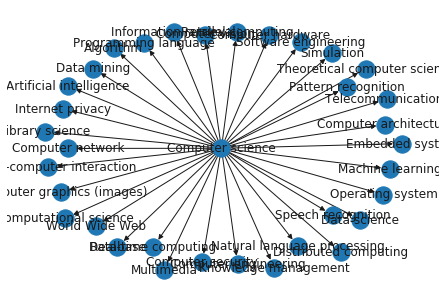

In [129]:
nx.draw(cs, pos=nx.spring_layout(cs), labels={n:cs.nodes[n]["Name"] for n in list(cs.nodes)})

In [133]:
ml.number_of_edges()

189

In [134]:
ml.number_of_nodes()

185

In [ ]:
virology.number_of_nodes()

In [ ]:
virology.number_of_edges()

In [ ]:
data

In [235]:
import requests as req

resp = req.get("https://www.fxp.co.il/showthread.php?t=20162737")


In [229]:
import re

In [240]:
len(re.findall(r'<li class=\"postbit postbitim postcontainer\".*?>(.+?)</li>',resp.text, re.S))

15

In [224]:
!wget https://www.fxp.co.il/showthread.php?t=20162737

--2020-03-16 14:29:04--  https://www.fxp.co.il/showthread.php?t=20162737
Resolving www.fxp.co.il (www.fxp.co.il)... 104.20.247.10, 104.20.246.10, 2606:4700:10::6814:f70a, ...
Connecting to www.fxp.co.il (www.fxp.co.il)|104.20.247.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 120066 (117K) [text/html]
Saving to: 'showthread.php?t=20162737'

100%[======================================>] 120,066     --.-K/s   in 0.06s   

2020-03-16 14:29:04 (1.88 MB/s) - 'showthread.php?t=20162737' saved [120066/120066]



In [90]:
_attrs = dict(id='id', children='children')

def tree_data(G, root, attrs=_attrs):
    if not G.is_directed():
        raise TypeError("G is not directed.")

    id_ = attrs['id']
    children = attrs['children']
    if id_ == children:
        raise nx.NetworkXError('Attribute names are not unique.')

    def add_children(n, G):
        nbrs = G[n]
        if len(nbrs) == 0:
            return []
        children_ = []
        for child in nbrs:
            d = dict(chain(G.nodes[child].items(), [(id_, child)]))
            c = add_children(child, G)
            if c:
                d[children] = c
            children_.append(d)
        return children_

    data = dict(chain(G.nodes[root].items(), [(id_, root)]))
    data[children] = add_children(root, G)
    return data


In [135]:
# from networkx.readwrite import json_graph
import json

data = tree_data(ml,root=119857082)
s = json.dumps(data)
with open("output/ml.json", "w") as f:
    f.write(s)

In [ ]:
mag.fields_of_study[mag.fields_of_study["FieldOfStudyId"]==956191]

In [141]:
paper_fields = mag.paper_fields_of_study.filter_by(nodes, "FieldOfStudyId")

In [142]:
paper_fields_filtered = paper_fields[paper_fields["Score"]>0.4]

In [143]:
papers = load_sframe("Data/mag/papers_loc.sframe")
papers["Year"] = papers["Year"].astype(int)
papers = papers[papers["num_countries"] > 0]
papers = papers.join(paper_fields_filtered, on="PaperId")

In [146]:
papers["Countries"] = papers["Dict of AuthorId_Country"].apply(lambda x: set(x.values()))
sf = papers.stack("Countries", "Country")
papers_agg =sf.groupby(["Country","Year","FieldOfStudyId"],agg.COUNT())
papers_agg =papers_agg.to_dataframe()
papers_agg_max = papers_agg.loc[papers_agg.groupby(['FieldOfStudyId', "Year"])['Count'].nlargest(1).reset_index()["level_2"]]

In [156]:
# papers_agg_max
papers_agg_max.groupby(["Year", "Country"]).count().reset_index().to_json("output/test.json",orient="records")

In [165]:
papers_agg_max.groupby(["Year", "Country"]).count().reset_index(1)

,Country,FieldOfStudyId,Count
Year,,,
1912,United States,1,1
1915,United States,1,1
1919,United States,1,1
1920,United States,1,1
1921,United States,1,1
1926,United States,1,1
1928,United States,1,1
1929,United States,1,1
1930,United Kingdom,1,1


In [164]:
papers_agg_max.groupby(["Year", "Country"]).count().reset_index(1).to_dict(orient="index")

ValueError: DataFrame index must be unique for orient='index'.

In [147]:
graphs = {}
for y, data in tqdm(papers_agg_max[papers_agg_max["Year"]>1950].groupby("Year")):
    g = ml.copy()
    sf = SFrame(data)
    filed_country = sf[["FieldOfStudyId","Country"]].unstack(["FieldOfStudyId","Country"])[["Dict of FieldOfStudyId_Country"]][0]['Dict of FieldOfStudyId_Country']
    nodes = list(g.nodes)
    for v in nodes:
        try:
            g.nodes[v]["Country"] = filed_country[v]
        except KeyError:
            g.remove_node(v)
    data = tree_data(g,root=119857082)
    graphs[y] = data


{'levels': [2], 'Name': 'Classifier (linguistics)'}
{'levels': [3], 'Name': 'Self-organizing map'}
{'levels': [2], 'Name': 'Swarm behaviour'}
{'levels': [2], 'Name': 'Variables'}
{'levels': [2], 'Name': 'Moderation'}
{'levels': [2], 'Name': 'Graphical model'}
{'levels': [2], 'Name': 'Intraclass correlation'}
{'levels': [2], 'Name': 'Combinatorial optimization'}
{'levels': [2], 'Name': 'Case-based reasoning'}
{'levels': [3], 'Name': 'Backpropagation'}
{'levels': [2], 'Name': 'Cointegration'}
{'levels': [2], 'Name': 'Anomaly detection'}
{'levels': [2], 'Name': 'Case analysis'}
{'levels': [2], 'Name': 'Particle swarm optimization'}
{'levels': [2], 'Name': 'Multi-agent system'}
{'levels': [3], 'Name': 'Multivariate normal distribution'}
{'levels': [2], 'Name': 'Exploratory factor analysis'}
{'levels': [2], 'Name': 'Test set'}
{'levels': [2], 'Name': 'Simulated annealing'}
{'levels': [2], 'Name': 'False positive paradox'}
{'levels': [2], 'Name': 'Rough set'}
{'levels': [2], 'Name': 'Video t

In [220]:
res = {}
for y, d in papers_agg_max.groupby(["Year", "Country"]).count().reset_index(1)[["Country","Count"]].groupby("Year"):
    res[y] = d.to_dict(orient="records")

In [201]:
SFrame(papers_agg_max.groupby(["Year", "Country"]).count().reset_index()).remove_column("FieldOfStudyId").unstack(["Country","Count"])

Year,Dict of Country_Count
1959,"{'Canada': 1, 'Germany':1, 'Japan': 1, 'Norway': ..."
1996,"{'Belgium': 1, 'France':1, 'Poland': 1, 'Spain': ..."
1935,"{'South Africa': 1,'United Kingdom': 2, ..."
1987,"{'Brazil': 1, 'Canada':2, 'Germany': 2, ..."
1939,"{'Australia': 1, 'UnitedKingdom': 2, 'United ..."
1958,"{'Australia': 1, 'India':1, 'Japan': 3, ..."
1976,"{'Australia': 2,'Belgium': 1, 'Canada': ..."
2012,"{'China': 63, 'India': 2,'Iran': 1, 'United ..."
1940,"{'Germany': 1, 'UnitedStates': 7} ..."
2015,"{'China': 74, 'India': 8,'United States': 101} ..."


In [196]:
graphs["agg"] = SFrame(papers_agg_max.groupby(["Year", "Country"]).count().reset_index()).remove_column("FieldOfStudyId").unstack(["Country","Count"]).unstack(["Year", "Dict of Country_Count"])[0]["Dict of Year_Dict of Country_Count"]

In [221]:
graphs["agg"] = res

In [222]:
import json
s = json.dumps(graphs)
with open("output/ml.json", "w") as f:
    f.write(s)

In [64]:
virology.to_

In [67]:
nx.to_pandas_edgelist(virology)

,source,target
0,159047783,4870876
1,159047783,10389963
2,159047783,22070199
3,159047783,64502627
4,159047783,71928629
5,159047783,85663871
6,159047783,99711299
7,159047783,112418997
8,159047783,114851261
9,159047783,116675565


In [243]:
papers.column_names()

['PaperId',
 'Rank',
 'Doi',
 'DocType',
 'PaperTitle',
 'OriginalTitle',
 'BookTitle',
 'Year',
 'Date',
 'Publisher',
 'JournalId',
 'ConferenceSeriesId',
 'ConferenceInstanceId',
 'Volume',
 'Issue',
 'FirstPage',
 'LastPage',
 'ReferenceCount',
 'CitationCount',
 'EstimatedCitation',
 'OriginalVenue',
 'CreatedDate',
 'Ref Number',
 'Total Citations by Year',
 'Total Citations by Year without Self Citations',
 'Authors List Sorted',
 'Authors Number',
 'Urls',
 'Dict of Year_Citation Number',
 'Field of study list',
 'Field of study list names',
 'Fields of study parent list (L0)',
 'Fields of study parent list names (L0)',
 'Fields of study parent list (L1)',
 'Fields of study parent list names (L1)',
 'Fields of study parent list (L2)',
 'Fields of study parent list names (L2)',
 'Fields of study parent list (L3)',
 'Fields of study parent list names (L3)',
 'Dict of AuthorId_Country',
 'num_countries',
 'Dict of AuthorId_City',
 'num_cities']

In [244]:
papers = load_sframe("Data/mag/papers_loc.sframe")
papers["Year"] = papers["Year"].astype(int)
papers = papers[papers["num_countries"] > 0]

In [ ]:
papers["Countries"] = papers["Dict of AuthorId_Country"].apply(lambda x: set(x.values()))
sf = papers.stack("Countries", "Country")

In [246]:

sf = sf.join(mag.paper_fields_of_study, on="PaperId")
papers_agg =sf.groupby(["Country","Year","FieldOfStudyId"],agg.COUNT())
papers_agg =papers_agg.to_dataframe()
papers_agg_max = papers_agg.loc[papers_agg.groupby(['FieldOfStudyId', "Year"])['Count'].nlargest(1).reset_index()["level_2"]]

In [248]:
sf.save("Data/mag/papers_loc_field.sframe")

In [250]:
papers_agg.to_csv("Data/mag/papers_agg.csv")

In [257]:
len(papers_agg_max[papers_agg_max["Count"]>100])

137777

In [259]:
papers2 = SFrame(papers_agg_max).filter_by(nodes, "FieldOfStudyId")

In [261]:
papers2.groupby("FieldOfStudyId",agg.SUM("Count"))

FieldOfStudyId,Sum of Count
169258074,2676
180075932,3258
27574286,8275
125403950,9587
122507166,3469
6841354,3520
5274069,5386
179717631,1647
176066374,1481
124066611,5246


In [263]:
mag.fields_of_study[mag.fields_of_study["FieldOfStudyId"]==179717631]

Columns:
	FieldOfStudyId	int
	Rank	int
	NormalizedName	str
	DisplayName	str
	MainType	str
	Level	int
	PaperCount	int
	CitationCount	int
	CreatedDate	str

Rows: Unknown

Data:
+----------------+-------+-----------------------+-----------------------+----------+
| FieldOfStudyId |  Rank |     NormalizedName    |      DisplayName      | MainType |
+----------------+-------+-----------------------+-----------------------+----------+
|   179717631    | 10111 | multilayer perceptron | Multilayer perceptron |   None   |
+----------------+-------+-----------------------+-----------------------+----------+
+-------+------------+---------------+-------------+
| Level | PaperCount | CitationCount | CreatedDate |
+-------+------------+---------------+-------------+
|   3   |   17050    |     231569    |  2016-06-24 |
+-------+------------+---------------+-------------+
[? rows x 9 columns]
Note: Only the head of the SFrame is printed. This SFrame is lazily evaluated.
You can use sf.materialize() to force materialization.

In [268]:
len(sf[sf["FieldOfStudyId"]==179717631])

11262

In [269]:
sf[sf["FieldOfStudyId"]==179717631]

PaperId,Rank,Doi,DocType,PaperTitle,OriginalTitle
2021004711,22727,10.1023/A:1014385916091,Journal,the supervised networkself organizing map for ...,The Supervised NetworkSelf-Organizing Map for ...
2062593995,19985,10.1016/j.eswa.2007.09.007 ...,Journal,a new approach forepileptic seizure ...,A new approach forepileptic seizure ...
2155426389,21622,10.1007/s11001-010-9101-1,Journal,preference of echofeatures for ...,Preference of echofeatures for ...
2155430354,20753,10.1109/PSCE.2009.4840226,Conference,ann based protectionsystem for controllable ...,ANN-based protectionsystem for Controllable ...
2155437399,21323,10.1109/PTC.2001.964937,Conference,short term loadforecasting of iran ...,Short term loadforecasting of Iran ...
2155452822,20918,10.1109/ITSC.2008.4732545,Conference,on integration offeatures and classifiers ...,On Integration ofFeatures and Classifiers ...
202635042,21405,,Conference,a method for time seriesprediction using a ...,A Method for Time SeriesPrediction using a ...
1596584754,22956,10.1109/IJCNN.2005.1556045 ...,Conference,sparse bayesian learningand the relevance multi ...,Sparse Bayesian learningand the relevance multi- ...
1649810345,23779,,Conference,static and dynamicclassification methods ...,Static and dynamicclassification methods ...
2062625481,21274,10.1016/S0006-3495(99)76967-5 ...,Journal,the kautsky curve is abuilt in barcode ...,The Kautsky Curve Is aBuilt-in Barcode ...


In [271]:
papers_fos_max = SFrame(papers_agg_max).join( mag.fields_of_study[ mag.fields_of_study["PaperCount"]>10000], on="FieldOfStudyId")

In [272]:
import concurrent.futures
import urllib.request
 
URLS = ['http://www.foxnews.com/',
        'http://www.cnn.com/',
        'http://europe.wsj.com/',
        'http://www.bbc.co.uk/',
        'http://some-made-up-domain.com/']
 
# Retrieve a single page and report the url and contents
def load_url(url, timeout):
    with urllib.request.urlopen(url, timeout=timeout) as conn:
        return conn.read()
 
# We can use a with statement to ensure threads are cleaned up promptly
with concurrent.futures.ThreadPoolExecutor(max_workers=5) as executor:
    # Start the load operations and mark each future with its URL
    future_to_url = {executor.submit(load_url, url, 60): url for url in URLS}
    for future in concurrent.futures.as_completed(future_to_url):
        url = future_to_url[future]
        try:
            data = future.result()
        except Exception as exc:
            print('%r generated an exception: %s' % (url, exc))
        else:
            print('%r page is %d bytes' % (url, len(data)))

'http://some-made-up-domain.com/' generated an exception: <urlopen error [Errno -2] Name or service not known>
'http://www.foxnews.com/' page is 220228 bytes
'http://www.bbc.co.uk/' page is 261398 bytes
'http://www.cnn.com/' page is 1138710 bytes
'http://europe.wsj.com/' generated an exception: HTTP Error 404: Not Found


In [281]:
papers_fos_max[papers_fos_max["Country"]=="China"].sort(["Year", "Count"],False)

Country,FieldOfStudyId,Year,Count,Rank,NormalizedName,DisplayName,MainType,Level
China,185592680,2019,25825,6802,chemistry,Chemistry,None,0
China,192562407,2019,16377,6772,materials science,Materials science,None,0
China,179104552,2019,12943,9230,inorganic chemistry,Inorganic chemistry,None,1
China,33923547,2019,9724,7258,mathematics,Mathematics,None,0
China,159985019,2019,8591,7192,composite material,Composite material,None,1
China,55493867,2019,6230,7381,biochemistry,Biochemistry,None,1
China,121332964,2019,5771,6669,physics,Physics,None,0
China,127413603,2019,5036,25000,engineering,Engineering,business.industry,0
China,178790620,2019,4415,8840,organic chemistry,Organic chemistry,None,1
China,153911025,2019,4164,7138,molecular biology,Molecular biology,None,1


In [283]:
t = papers_fos_max.groupby(["Country", "Year"],agg.COUNT())

In [286]:
t.sort(["Year", "Count"], False)

Country,Year,Count
United States,2019,5786
China,2019,4494
India,2019,403
United Kingdom,2019,326
Germany,2019,103
Australia,2019,64
Brazil,2019,60
Japan,2019,57
Italy,2019,52
Iran,2019,39


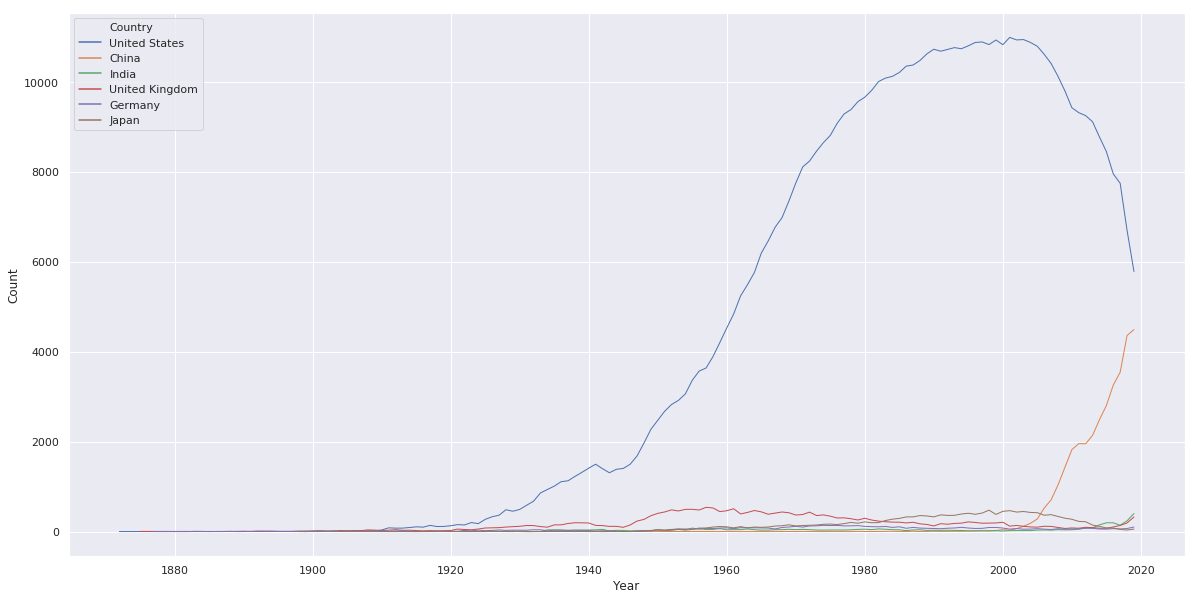

In [315]:
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
df = t.filter_by(c,"Country").sort(["Year", "Count"], False)[["Year", "Count","Country"]].to_dataframe()
plt.figure(figsize=(20,10))

ax = sns.lineplot(x="Year", y="Count", hue="Country", estimator=None, lw=1,
                  data=df)

In [287]:
t2 = papers_fos_max.groupby(["Country", "Year", "Level"],agg.COUNT())

In [288]:
t2.filter_by(0,"Level").sort(["Year", "Count"], False)

Country,Level,Year,Count
United States,0,2019,12
China,0,2019,6
Germany,0,2019,1
United States,0,2018,14
China,0,2018,5
United States,0,2017,16
China,0,2017,3
United States,0,2016,16
China,0,2016,3
United States,0,2015,16


In [289]:
t2.filter_by(1,"Level").sort(["Year", "Count"], False)

Country,Level,Year,Count
United States,1,2019,200
China,1,2019,86
Germany,1,2019,3
United Kingdom,1,2019,3
India,1,2019,2
United States,1,2018,223
China,1,2018,68
Germany,1,2018,2
France,1,2018,1
United States,1,2017,240


In [290]:
t2.filter_by(2,"Level").sort(["Year", "Count"], False)

Country,Level,Year,Count
United States,2,2019,3205
China,2,2019,2501
United Kingdom,2,2019,206
India,2,2019,175
Germany,2,2019,46
Brazil,2,2019,40
Australia,2,2019,34
Italy,2,2019,27
Japan,2,2019,21
Spain,2,2019,21


In [296]:
t2.filter_by(2,"Level").filter_by(2010,"Year").sort(["Year", "Count"], False)

Country,Level,Year,Count
United States,2,2010,5231
China,2,2010,858
Japan,2,2010,150
United Kingdom,2,2010,53
Brazil,2,2010,37
Germany,2,2010,34
India,2,2010,17
France,2,2010,16
South Korea,2,2010,12
Spain,2,2010,12


In [297]:
c = ["United States","Japan", "China","United Kingdom","Germany","India"]

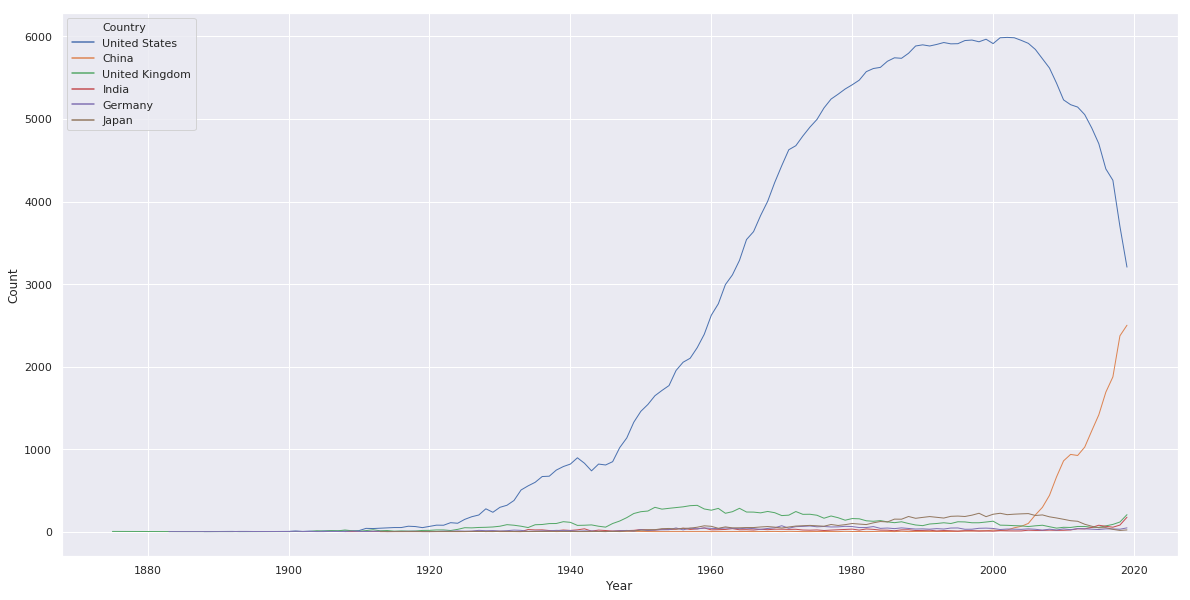

In [313]:
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
df = t2.filter_by(2,"Level").filter_by(c,"Country").sort(["Year", "Count"], False)[["Year", "Count","Country"]].to_dataframe()
plt.figure(figsize=(20,10))

ax = sns.lineplot(x="Year", y="Count", hue="Country", estimator=None, lw=1,
                  data=df)

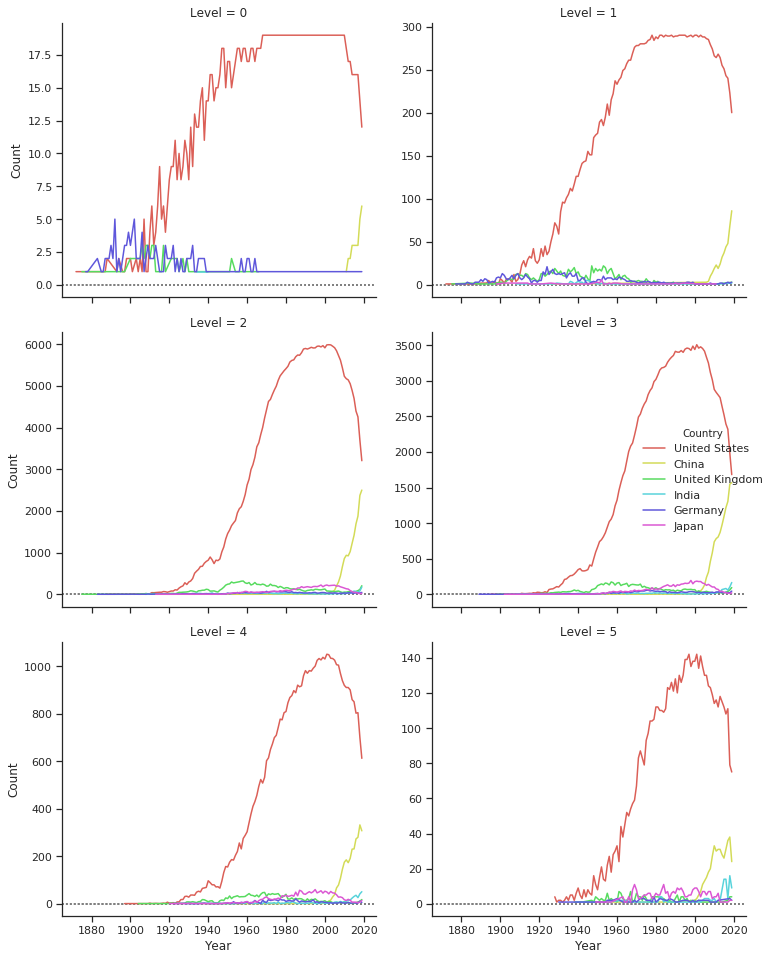

In [326]:
create_gird(t2.filter_by(c,"Country").sort(["Year", "Count"],False).to_dataframe(),"Level","Country","Year","Count",False,True)

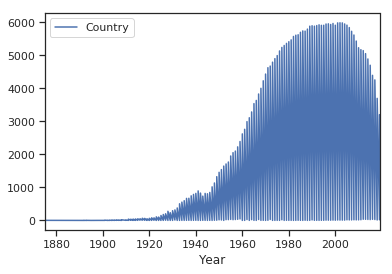

In [311]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
t2.filter_by(2,"Level").filter_by(c,"Country").sort(["Year", "Count"], False)[["Year", "Count","Country"]].to_dataframe().groupby('Country').plot(x="Year",y="Count",ax=ax, label="Country")

In [331]:
from langdetect import detect
detect("вавав")

'ru'

In [333]:
len(papers)

31410585

In [336]:
extended_papers =mag.extended_papers

In [337]:
extended_papers

PaperId,Rank,Doi,DocType,PaperTitle,OriginalTitle
1968760011,23280,10.1080/09593339209385258,Journal,bod and cod removal inwaste stabilization p ...,Bod and cod removal inwaste stabilization p ...
2140101301,21822,,,brain research andreading how emerging ...,Brain research andreading: How emerging ...
2374592160,24375,,Journal,analysis on factorsrestricting chinese ...,Analysis on FactorsRestricting Chinese ...
140507261,22889,,Journal,needle free injectionscience fiction or ...,[Needle-free injection--science fiction or ...
1979425243,21415,10.1038/emm.2004.13,Journal,kinesin superfamilyprotein member 4 kif4 is ...,Kinesin superfamilyprotein member 4 (KIF4) ...
2067955817,23976,10.1002/j.1537-2197.1991.tb15202.x ...,Journal,differential rnasynthesis in the shoot ...,Differential RNAsynthesis in the shoot ...
1968760012,26310,10.1093/aesa/63.1.100,Journal,effect of age onrespiration and ...,Effect of Age onRespiration and ...
2140101310,20132,10.1002/mrm.24162,Journal,a unified impulseresponse model for dce ...,A unified impulseresponse model for DCE- ...
2374592165,25123,,Journal,the design of sip mappingmechanism in parlay osa ...,The Design of SIP MappingMechanism in Parlay/OSA ...
140507263,26982,,,mutagenesis on isolateddna induced by ...,"MUTAGENESIS ON ISOLATEDDNA, INDUCED BY ..."


In [342]:
extended_papers["lang"] = extended_papers["OriginalTitle"].apply(lambda x: detect(x))

In [ ]:
len(extended_papers[extended_papers["lang"]=="ru"])

In [339]:
mag.urls

PaperId,Urls
2739614902,[https://www.gerad.ca/en/papers/G-97-15] ...
2052959059,[http://pubsdc3.acs.org/doi/abs/10.1021/jp8050 ...
2846717302,[https://lens.org/017-758-495-336-426] ...
2318441961,[https://link.springer.com/article/10.1007/BF0 ...
36401732,[https://link.springer.com/chapter/10.1007/3-5 ...
2825801101,[https://lens.org/044-966-986-630-326] ...
1587195125,[http://repository.uwyo.edu/cgi/viewcontent.cg ...
874051506,[http://www.koreascience.or.kr/article/Article ...
562099596,[http://ci.nii.ac.jp/naid/40016848692] ...
1583875383,[https://www.tandfonline.com/doi/full/10.1080/ ...


In [341]:
cols = ["PaperId", "SourceType", "SourceUrl", "LanguageCode"]

urls = SFrame(pd.read_csv(mag._dataset_dir / "PaperUrls.txt.gz", sep="\t",
                            names=cols).replace({pd.np.nan: None}))

KeyboardInterrupt: 